# 01 · Weather EDA: Mumbai heat stress
Exploratory look at the data behind HeatShield. Every number below is computed from the files downloaded by `python -m heatshield.ingest.stations` and `python -m heatshield.ingest.weather`, then `python -m heatshield.features.daily`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from heatshield.config import DATA_PROCESSED, DATA_RAW
pd.set_option('display.width', 160)
obs = pd.read_parquet(DATA_PROCESSED/'obs_daily.parquet')
fc = pd.read_parquet(DATA_PROCESSED/'fc_daily.parquet')
era5 = pd.read_parquet(DATA_PROCESSED/'era5_daily.parquet')
hourly = pd.read_parquet(DATA_RAW/'obs_hourly.parquet')
print(hourly.groupby('station')['time'].agg(['min','max','count']))

                          min                 max  count
station                                                 
colaba    2021-01-01 05:30:00 2026-11-14 20:30:00   7750
santacruz 2021-01-01 00:30:00 2026-11-14 22:30:00  50879


## 1. How complete are the station observations?
Santacruz reports hourly; Colaba only at synoptic hours. A day counts as *valid* only if it has enough afternoon reports to trust the daily maximum (rules in `features/daily.py`).

In [2]:
cov = obs.groupby(['station', obs.date.dt.year])['valid'].agg(['sum','size'])
cov['share_valid'] = (cov['sum']/cov['size']).round(3)
cov

sum  size  share_valid
station   date                        
colaba    2021   89   364        0.245
          2022  165   365        0.452
          2023  114   363        0.314
          2024  284   363        0.782
          2025  356   362        0.983
          2026  307   308        0.997
santacruz 2021  363   365        0.995
          2022  365   365        1.000
          2023  363   365        0.995
          2024  363   366        0.992
          2025  348   365        0.953
          2026  315   315        1.000

In [3]:
hourly['hour'] = hourly.time.dt.hour
hourly[hourly.station=='colaba'].hour.value_counts().sort_index()

hour
2        1
5      618
8     2108
10       1
11    1189
14     988
17    2101
20     744
Name: count, dtype: int64

## 2. The seasonal cycle: why humidity matters
Monthly averages of the daily maximum temperature and the daily maximum **heat index** at Santacruz (valid days, 2021–2026). The gap between the two is the extra stress from humidity.

In [4]:
s = obs[(obs.station=='santacruz') & obs.valid].copy()
m = s.groupby(s.date.dt.month)[['tmax','hi_max','rh_at_tmax']].mean().round(1)
m['humidity_penalty'] = (m.hi_max - m.tmax).round(1)
m

,tmax,hi_max,rh_at_tmax,humidity_penalty
date,,,,
1,30.7,31.4,41.2,0.7
2,32.8,32.9,34.0,0.1
3,34.1,36.2,38.4,2.1
4,34.0,40.0,51.0,6.0
5,33.8,41.9,59.3,8.1
6,32.6,41.1,67.2,8.5
7,29.9,37.7,80.2,7.8
8,30.2,37.1,74.8,6.9
9,30.3,37.3,74.2,7.0


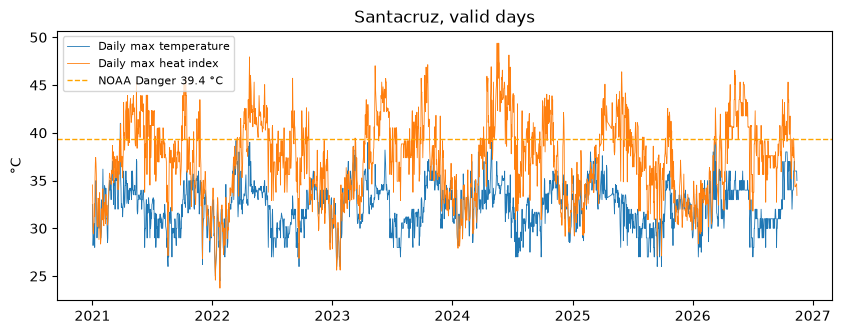

In [5]:
fig, ax = plt.subplots(figsize=(10,3.5))
ax.plot(s.date, s.tmax, lw=.6, label='Daily max temperature')
ax.plot(s.date, s.hi_max, lw=.6, label='Daily max heat index')
ax.axhline(39.4, color='orange', ls='--', lw=1, label='NOAA Danger 39.4 °C')
ax.set_ylabel('°C'); ax.legend(fontsize=8); ax.set_title('Santacruz, valid days'); plt.show()

In [6]:
print('Share of valid Santacruz days at NOAA Danger or worse, by year:')
print((s.hi_max >= 39.4).groupby(s.date.dt.year).mean().round(3))

Share of valid Santacruz days at NOAA Danger or worse, by year:
date
2021    0.278
2022    0.268
2023    0.295
2024    0.355
2025    0.241
2026    0.321
Name: hi_max, dtype: float64


## 3. ERA5 vs the station
ERA5 is a ~25 km grid box that includes sea, so it should run cooler than the station. This is why the climate *normal* (from ERA5) is shifted to station level before comparing.

In [7]:
j = s.merge(era5[['date','tmax','hi_max']], on='date', suffixes=('_stn','_era5'))
j['diff_hi'] = j.hi_max_stn - j.hi_max_era5
print('days compared:', len(j))
print('mean station - ERA5 heat index: %.2f °C' % j.diff_hi.mean())
print('mean station - ERA5 Tmax:       %.2f °C' % (j.tmax_stn - j.tmax_era5).mean())
j.groupby(j.date.dt.month).diff_hi.mean().round(2)

days compared: 2115
mean station - ERA5 heat index: 2.36 °C
mean station - ERA5 Tmax:       1.60 °C


date
1     1.49
2     1.50
3     1.79
4     2.20
5     2.06
6     3.11
7     3.50
8     3.17
9     2.99
10    2.66
11    1.82
12    1.82
Name: diff_hi, dtype: float64

## 4. Long-term context (ERA5, 1991 → today)
Annual mean of the daily max heat index from ERA5 (ERA5 level, not station level).

Linear trend 1991-2025: 0.65 °C per decade


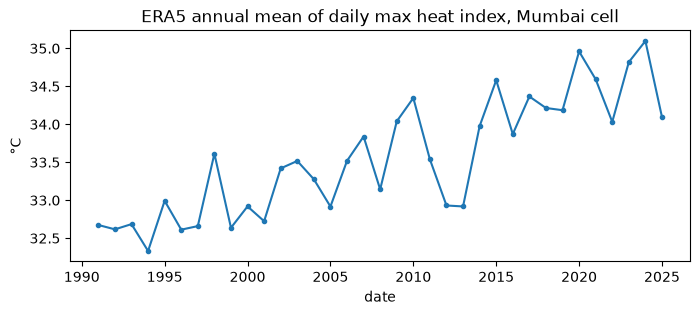

In [8]:
yr = era5.groupby(era5.date.dt.year).hi_max.mean()
full_years = yr.loc[:2025]
slope = np.polyfit(full_years.index, full_years.values, 1)[0]
print('Linear trend 1991-2025: %.2f °C per decade' % (slope*10))
ax = full_years.plot(figsize=(8,3), marker='o', ms=3, title='ERA5 annual mean of daily max heat index, Mumbai cell')
ax.set_ylabel('°C'); plt.show()

## 5. How good are the raw forecasts?
Daily max heat index from each archived model vs the Santacruz observation, on days where **all four** models have a forecast (fair comparison). Positive bias = forecast too hot.

In [9]:
o = s[['date','hi_max']]
f = fc[fc.station=='santacruz'].merge(o, on='date', suffixes=('_fc','_obs'))
f = f[f.groupby(['lead_days','date']).model.transform('nunique')==4]
f['err'] = f.hi_max_fc - f.hi_max_obs
summary = f.groupby(['model','lead_days']).err.agg(mae=lambda e: e.abs().mean(), bias='mean').round(2)
summary.unstack('lead_days')

mae                          bias                        
lead_days        1     2     3     4     5     1     2     3     4     5
model                                                                   
ecmwf_ifs025  3.16  3.12  3.15  3.06  3.10 -3.01 -2.97 -3.01 -2.88 -2.89
gfs_seamless  3.44  3.61  3.67  3.62  3.76 -3.37 -3.54 -3.60 -3.53 -3.66
icon_global   3.27  3.33  3.33  3.42  3.43 -3.10 -3.14 -3.08 -3.21 -3.21
jma_gsm       3.88  3.91  3.98  3.98  3.98 -3.83 -3.85 -3.92 -3.92 -3.91

## Takeaways
- All four global models are biased **cool** at Santacruz (negative bias in the table above), so the error is systematic, which is exactly what a statistical corrector can learn.
- Humidity adds several °C of felt heat in the pre-monsoon and October months (table in section 2).
- ERA5 is cooler than the station, so normals must be shifted to station level (section 3).
- Colaba has only daytime synoptic reports, so it is used as a secondary check, not the main target.